# Libraries

In [ ]:
!pip install qutip

In [ ]:
from qutip import *
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset


#  Cavity blockade: a way to make photons interact

In this exercise you will explore a regime in which a cavity, once filled with a single photon, blocks the possibility to insert another one. This can be effectively interpreted as a photon-photon interaction mediated by the atom in the cavity, a possibility that photons in vacuum do not have (the photon-photon cross section predicted by QED in vacuum is extremely small). The first observation of this phenomenon was done in Birnbaum et al. Nature 436, 87 (2005).

A driven cavity is described by a Jaynes-Cummings model
$$\hat{H} = \hbar \omega_c \hat{a}^\dagger \hat{a} + \hbar \omega_a |e\rangle\langle e| + \hbar \tilde{g} (\hat{\sigma}_+ \hat{a} + \hat{\sigma}_- \hat{a}^\dagger) + \hat{H}_d ,$$
where $\hat{H}_d = E e^{i\omega t} \hat{a} + \text{h.c.}$ is a (pumping) driving field.

1. Explain the physical meaning of $\hat{H}_d$. How would you realize such a term?
2. Rewrite the hamiltonian in the frame of the drive and use the RWA.

Consider $\omega = \omega_a = \omega_c$ and no coupling between cavity and atom, $\tilde{g} = 0$. Given an initially empty cavity, $|g, 0\rangle$, you will numerically solve the corresponding master equation at resonance (you can use the QuTiP library). Assume a small decay rate of the atom in the photon modes outside the cavity, $\Gamma$, and assume also that the cavity is not perfect and can lose photons with a small decay rate $\kappa$.

3. Integrate the master equation for enough large times to find the steady state. What is the mean photon number $\langle \hat{a}^\dagger \hat{a} \rangle$? What is the steady-state occupation of the $n$-photon states? Plot the histogram of occupations and compare with a coherent state distribution.
   [*Suggestion:* work in a regime of parameters that allow you to keep the photon Hilbert space sufficiently small (e.g. max 10 - 50 photon states) and the average photon number of the steady state small, $\langle \hat{a}^\dagger \hat{a} \rangle \le 10$. Explain how you made your choice.]
4. In the presence of a coupling $\tilde{g}$, the previous resonance condition is not valid anymore. Set $\omega$ to resonance with the lowest (one-photon) dressed state of the Jaynes-Cummings model and find again the steady state in the strong-coupling condition $\tilde{g} \gg \Gamma, \kappa$ and weak drive $E$. How important is the value of the pumping strength $E$? (Be careful that increasing $E$ too much could lead to instability/bistability)
5. Can you have occupation of two photon states? If not, why? What happens if you increase the values of the decay rates? And if you change $\tilde{g}$?
6. A way to understand the suppression of two-photon states is to compute the two-photon correlation function $g^{(2)} \equiv \langle \hat{a}^\dagger \hat{a}^\dagger \hat{a} \hat{a} \rangle / |\langle \hat{a}^\dagger \hat{a} \rangle|^2$, which compares the probability to find two simultaneous photons with the one of having two independent photons at random. In the blockade regime, you should find $g^{(2)} < 1$.
7. Scan the values of $\omega$ around the resonance and graphically represent your findings as in Fig. 2a of the paper by Birnbaum et al.
8. *(Bonus)* Can you make analytical predictions for the steady state in a convenient regime?

# 1. Physical Meaning of $\hat{H}_d$


$\hat{H}_d$ represent an object that adds photons to the cavity, in particular, it represents a monochromatic laser. The latter can be understood by considering the following:
- There is just one drive's frequency, so the laser is monochromatic

- We will observe in the following points of the exercise that the drive induces and then mantain a coherent state in the cavity

# 2. Hamiltonian in the drive's frame


The Hamiltonian of the system is:
$$\hat{H}(t) = \hbar \omega_c \hat{a}^\dagger\hat{a}+\hbar \omega_a |e\rangle \langle e | + \hbar \tilde{g}(\hat{\sigma}_+  \hat{a}+ \hat{\sigma}_- \hat{a}^\dagger) + \hat{H}_d$$
where $\hat{H}_d = \varepsilon (e^{i\omega t}\hat{a}+ e^{-i\omega t}\hat{a}^\dagger)$ is the drive Hamiltonian.

In order to remove the temporal dependency of the Hamiltonian, we move to the drive's frame using the operator:
$$R(t)= \exp\left[i \omega t(|e\rangle \langle e|+\hat{a}^\dagger \hat{a})\right]≡ e^{K(t)}$$


So the Hamiltonian in the new frame is:
$$\hat{H}'(t)= R(t)H(t)R(t)^\dagger - i\hbar R(t) \dot{R}^\dagger(t)$$

Reminding Hadamard's lemma:
$$e^{A}Be^{-A}= B + [A,B]+\frac{1}{2!}[A,[A,B]]+\frac{1}{3!}[A,[A,[A,B]]]+...$$

We obtain:

$$\hat{H}'(t)= -i\hbar R(t) \dot{R}^\dagger(t)+\hat{H}(t) + [K,\hat{H}](t) + \frac{1}{2!}[K,[K,\hat{H}]](t) +\frac{1}{3!}[K,[K,[K,\hat{H}]]](t)+...$$

Let's compute part by part the components of the Hamiltonian:

$$-i\hbar R(t) \dot{R}^\dagger(t)=-i\hbar R(t)\left[ -i  \omega (|e\rangle \langle e|+\hat{a}^\dagger \hat{a})\right]R^\dagger(t)= -\hbar \omega  R(t)(|e\rangle \langle e|+\hat{a}^\dagger \hat{a})R^\dagger (t) = -\hbar \omega  (|e\rangle \langle e|+\hat{a}^\dagger \hat{a})$$

Where I used $[|e\rangle \langle e|, i \omega t(|e\rangle \langle e|+\hat{a}^\dagger \hat{a})]=0 $ since $|e\rangle \langle e|$ commutes with itself and with $\hat{a}^\dagger \hat{a}$ since they act on different degrees of freedom.
For $[\hat{a}^\dagger \hat{a}, i \omega t(|e\rangle \langle e|+\hat{a}^\dagger \hat{a})]=0 $ for the very same reason.


Let's compute the rest:

*First Term*
$$ \hbar \omega_c \hat{a}^\dagger\hat{a} + \hbar \omega_c [K,  \hat{a}^\dagger\hat{a}](t)+ \frac{(\hbar \omega_c)^2}{2!}[K,[K, \hat{a}^\dagger\hat{a}]](t) + ... = \hbar \omega_c \hat{a}^\dagger\hat{a} $$

*Second Term*

$$\hbar \omega_a |e\rangle \langle e | + \hbar \omega_a [K, |e\rangle \langle e |](t) + \frac{(\hbar \omega_a)^2}{2!}[K, [K, |e\rangle \langle e |]](t) + ... = \hbar \omega_a |e\rangle \langle e | $$

Where I used the fact that $[K, |e\rangle \langle e |]=0$ since $K$ acts in the light's state space and $|e\rangle \langle e |$ on the atom's state space.

*Third Term*

$$[i \omega t(|e\rangle \langle e|+\hat{a}^\dagger \hat{a}), \hbar \tilde{g}(\hat{\sigma}_+  \hat{a}+ \hat{\sigma}_- \hat{a}^\dagger)]= i \hbar \omega \tilde{g} t \left([|e\rangle \langle e|,(\hat{\sigma}_+  \hat{a}+ \hat{\sigma}_- \hat{a}^\dagger)] + [\hat{a}^\dagger \hat{a},(\hat{\sigma}_+  \hat{a}+ \hat{\sigma}_- \hat{a}^\dagger)] \right) = $$

$$ = i \hbar \omega \tilde{g} t \left[ \left(\hat{\sigma}_+  \hat{a} - \hat{\sigma}_- \hat{a}^\dagger \right) + \left(\hat{\sigma}_+  [\hat{a}^\dagger, \hat{a}]\hat{a} + \hat{\sigma}_- \hat{a}^\dagger[ \hat{a},\hat{a}^\dagger]  \right)\right] =  i \hbar \omega \tilde{g} t \left[ \left(\hat{\sigma}_+  \hat{a} - \hat{\sigma}_- \hat{a}^\dagger \right)- \left(\hat{\sigma}_+  \hat{a} - \hat{\sigma}_- \hat{a}^\dagger \right)\right] = 0$$

$$ \hbar \tilde{g}(\hat{\sigma}_+  \hat{a}+ \hat{\sigma}_- \hat{a}^\dagger) +  [K,  \hbar \tilde{g}(\hat{\sigma}_+  \hat{a}+ \hat{\sigma}_- \hat{a}^\dagger)](t) + \frac{1}{2!}[K, [K, \hbar \tilde{g}(\hat{\sigma}_+  \hat{a}+ \hat{\sigma}_- \hat{a}^\dagger)]](t) + ...=  \hbar \tilde{g}(\hat{\sigma}_+  \hat{a}+ \hat{\sigma}_- \hat{a}^\dagger) $$


*Last term*
$$ [i \omega t(|e\rangle \langle e|+\hat{a}^\dagger \hat{a}),  \varepsilon (e^{i\omega t}\hat{a}+ e^{-i\omega t}\hat{a}^\dagger)] = i\omega t \varepsilon \left( e^{i\omega t} [\hat{a}^\dagger \hat{a}, \hat{a}]+ e^{-i\omega t}[\hat{a}^\dagger \hat{a}, \hat{a}^\dagger]\right)=$$

$$=i\omega t \varepsilon \left( e^{i\omega t} [\hat{a}^\dagger, \hat{a}] \hat{a}+ e^{-i\omega t}\hat{a}^ \dagger[\hat{a}, \hat{a}^\dagger]\right) = i\omega t \varepsilon \left( -e^{i\omega t} \hat{a}+ e^{-i\omega t}\hat{a}^ \dagger\right)$$

$$ [K,[K, \hat{H}_d]](t)= [i \omega t(|e\rangle \langle e|+\hat{a}^\dagger \hat{a}),  i\omega t \varepsilon \left( -e^{i\omega t} \hat{a}+ e^{-i\omega t}\hat{a}^ \dagger\right)] = -(\omega t)^2 \varepsilon \left( +e^{i\omega t} \hat{a}+ e^{-i\omega t}\hat{a}^ \dagger\right)$$

So:
$$\hat{H}_d + [K, \hat{H}_d](t) + \frac{1}{2!}[K,[K, \hat{H}_d]](t) + ... = $$
$$=\hat{H}_d \cos(\omega t) + i \varepsilon\sin(\omega t)\left( -e^{i\omega t} \hat{a}+ e^{-i\omega t}\hat{a}^ \dagger\right) = $$
$$= e^{i \omega t} \varepsilon[\cos(\omega t) - i \sin(\omega t)] \hat{a} + e^{-i \omega t} \varepsilon[\cos(\omega t) + i \sin(\omega t)] \hat{a}^\dagger=$$
$$=e^{i \omega t} e^{-i \omega t}\varepsilon \hat{a} + e^{-i \omega t}e^{i \omega t} \varepsilon \hat{a}^\dagger=  \varepsilon (\hat{a} + \hat{a}^\dagger)$$
Putting all togheter:

$$\hat{H}'(t) = \hat{H}'=\hbar (\omega_c-\omega) \hat{a}^\dagger\hat{a} + \hbar (\omega_a-\omega) |e\rangle \langle e | + \hbar \tilde{g}(\hat{\sigma}_+  \hat{a}+ \hat{\sigma}_- \hat{a}^\dagger) + \varepsilon (\hat{a} + \hat{a}^\dagger)$$

# 3. Integrating the Master Equation
 $$\hat{H}'=\hbar (\omega_c-\omega) \hat{a}^\dagger\hat{a} + \hbar (\omega_a-\omega) |e\rangle \langle e | + \hbar \tilde{g}(\hat{\sigma}_+  \hat{a}+ \hat{\sigma}_- \hat{a}^\dagger) + \varepsilon (\hat{a} + \hat{a}^\dagger)$$

 For $\omega = \omega_a = \omega_c \equiv \omega_0$ and $\tilde{g} = 0$:

  $$\hat{H}'= \varepsilon (\hat{a} + \hat{a}^\dagger)$$

We solve it numerically:


## 3.1 Solving Bloch Optical Equations for the Cavity

Lindblad equation for our system.
$$\dot\rho = \frac{i}{\hbar}[\rho, H] + \frac{\kappa}{2}\left[2a\rho a^\dagger - \{a^\dagger a, \rho\}\right]$$

Our aim is to compute:
$$\frac{d}{dt}\langle a^\dagger a \rangle = \text{Tr}[\dot\rho\, a^\dagger a]$$

So that we can compute the value of $\langle a^\dagger a \rangle$ for the steady state as well.

### *First term*

$$\text{Tr}\left[\frac{i}{\hbar}[\rho,H]\,a^\dagger a\right] = \frac{i}{\hbar}\text{Tr}(\rho Ha^\dagger a) - \frac{i}{\hbar}\text{Tr}(\rho a^\dagger aH) = \frac{i}{\hbar}\text{Tr}\left(\rho[H, a^\dagger a]\right)$$

Con $H=\varepsilon(a+a^\dagger)$ e usando $[a,a^\dagger a]=a$, $[a^\dagger,a^\dagger a]=-a^\dagger$:

$$[H, a^\dagger a] = \varepsilon\left([a,a^\dagger a] + [a^\dagger,a^\dagger a]\right) = \varepsilon(a - a^\dagger)$$

$$\text{Tr}\left[\frac{i}{\hbar}[\rho,H]a^\dagger a\right] = \frac{i\varepsilon}{\hbar}\left(\langle a \rangle - \langle a^\dagger \rangle\right)$$

### *Second Term*

$$\frac{\kappa}{2}\text{Tr}\left[\left(2a\rho a^\dagger - a^\dagger a\rho - \rho a^\dagger a\right)a^\dagger a\right]$$

Using: $\text{Tr}(a\rho a^\dagger a^\dagger a)=\text{Tr}(\rho a^\dagger a^\dagger a a)$

$$= \kappa\,\text{Tr}\left(\rho a^\dagger a^\dagger a a\right) - \kappa\,\text{Tr}\left(\rho a^\dagger aa^\dagger a\right) = \kappa\,\text{Tr}\left[\rho a^\dagger\left(a^\dagger a a - a a^\dagger a\right)\right]$$

Con $a^\dagger aa - aa^\dagger a = (a^\dagger a - aa^\dagger)a = [a^\dagger,a]\,a=-a$:

$$= \kappa\,\text{Tr}\left[\rho a^\dagger(-a)\right] = -\kappa\,\text{Tr}(\rho a^\dagger a) = -\kappa\langle N \rangle$$

### *Final result*

$$\frac{d}{dt}\langle a^\dagger a \rangle = \frac{d}{dt}\langle N \rangle = \frac{i\varepsilon}{\hbar}\left(\langle a \rangle - \langle a^\dagger \rangle\right) - \kappa\langle N \rangle$$

We see that $\langle N \rangle$ depends on $\langle a \rangle$ and $\langle a^\dagger \rangle$. Let's compute the time derivative of these terms to solve the differential system.

---

$$\frac{d}{dt}\langle a \rangle = \text{Tr}[\dot\rho\, a]$$

### *First Term*

$$\text{Tr}\left(\frac{i}{\hbar}[\rho,H]a\right) = \frac{i}{\hbar}\text{Tr}(\rho Ha) - \frac{i}{\hbar}\text{Tr}(\rho aH) \quad \text{(using } \text{Tr}(ABC) = \text{Tr}(BCA)\text{)}$$

$$= \frac{i}{\hbar}\text{Tr}\left(\rho[H,a]\right)$$

Using $[H,a] = \varepsilon[a+a^\dagger, a] = \varepsilon[a^\dagger, a] = -\varepsilon$:

$$= \frac{i}{\hbar}\text{Tr}\left(\rho\cdot(-\varepsilon)\right) = -\frac{i\varepsilon}{\hbar}$$

### *Second term*

$$\frac{\kappa}{2}\text{Tr}\left[(2a\rho a^\dagger - a^\dagger a\rho - \rho a^\dagger a)a\right]$$

Using: $\text{Tr}(a\rho a^\dagger a)=\text{Tr}(\rho a^\dagger a\,a)$, $\text{Tr}(\rho a^\dagger a a)=\text{Tr}(\rho a^\dagger a\,a)$, and $\text{Tr}(a^\dagger a\rho a)=\text{Tr}(\rho a\,a^\dagger a)$:

$$= \frac{\kappa}{2}\left[2\,\text{Tr}(\rho a^\dagger a\, a) - \text{Tr}(\rho a\, a^\dagger a) - \text{Tr}(\rho a^\dagger a\, a)\right] = \frac{\kappa}{2}\text{Tr}\left(\rho[a^\dagger a,a]\right)$$

Con $\hat N=a^\dagger a$ e $[\hat N,a] = a^\dagger a a - a a^\dagger a = (a^\dagger a - aa^\dagger)a = -a$:

$$= \frac{\kappa}{2}\text{Tr}(-\rho a) = -\frac{\kappa}{2}\langle a \rangle$$

### *Result*

$$\frac{d}{dt}\langle a \rangle = -\frac{i\varepsilon}{\hbar} - \frac{\kappa}{2}\langle a \rangle$$

$$\frac{d}{dt}\langle a^\dagger \rangle = \frac{i\varepsilon}{\hbar} - \frac{\kappa}{2}\langle a^\dagger \rangle$$

---

### Computing the average value of photons for the steady state

$$\frac{d}{dt}\begin{pmatrix} \langle a \rangle \\ \langle a^\dagger \rangle \\ \langle N \rangle \end{pmatrix} = \begin{pmatrix} -\dfrac{\kappa}{2} & 0 & 0 \\[8pt] 0 & -\dfrac{\kappa}{2} & 0 \\[8pt] \dfrac{i\varepsilon}{\hbar} & -\dfrac{i\varepsilon}{\hbar} & -\kappa \end{pmatrix}\begin{pmatrix} \langle a \rangle \\ \langle a^\dagger \rangle \\ \langle N \rangle \end{pmatrix} + \begin{pmatrix} -\dfrac{i\varepsilon}{\hbar} \\[6pt] \dfrac{i\varepsilon}{\hbar} \\[6pt] 0 \end{pmatrix}$$

we define:
$$\vec S = \begin{pmatrix} \langle a \rangle \\ \langle a^\dagger \rangle \\ \langle N \rangle \end{pmatrix}, \qquad M = \begin{pmatrix} -\dfrac{\kappa}{2} & 0 & 0 \\[8pt] 0 & -\dfrac{\kappa}{2} & 0 \\[8pt] \dfrac{i\varepsilon}{\hbar} & -\dfrac{i\varepsilon}{\hbar} & -\kappa \end{pmatrix}, \qquad \vec R = \begin{pmatrix} -\dfrac{i\varepsilon}{\hbar} \\[6pt] \dfrac{i\varepsilon}{\hbar} \\[6pt] 0 \end{pmatrix}$$

For a stationary state:

$$\frac{d}{dt} \vec S(t \rightarrow \infty) = 0= M\vec S + \vec R$$
$$\vec S_{ss} = -M^{-1}\vec R$$

$$\vec S_{ss} = \begin{pmatrix} -\dfrac{2i\varepsilon}{\hbar\kappa} \\[8pt] \dfrac{2i\varepsilon}{\hbar\kappa} \\[8pt] \dfrac{4\varepsilon^2}{\hbar^2\kappa^2} \end{pmatrix}$$

## Code

In [ ]:
N = 20                    #hilbert space dim
a = destroy(N)            #ladder operator for the light

kappa = 1.0        # we fix the target average number and the decay rate k
n_target = 4.0     # and using the results of the bloch optical equation,
epsilon = kappa * np.sqrt(n_target) / 2   # we infer the value of epsilon

H = epsilon * (a + a.dag())             #the hamiltonian
c_ops = [np.sqrt(kappa) * a]            #collapse operators of the cavity

psi0 = fock(N, 0)                       #initial state

tlist = np.linspace(0, 40, 80)
result = mesolve(H, psi0, tlist, c_ops, e_ops=[a.dag() * a],
                 options={"store_states": True})

n_steady = np.real(result.expect[0][-1])

print(f"<n>_steady = {n_steady:.4f}, target = {n_target} (after 40 timesteps)")

<n>_steady = 4.0000, target = 4.0 (after 40 timesteps)


Text(0, 0.5, 'Photon number')

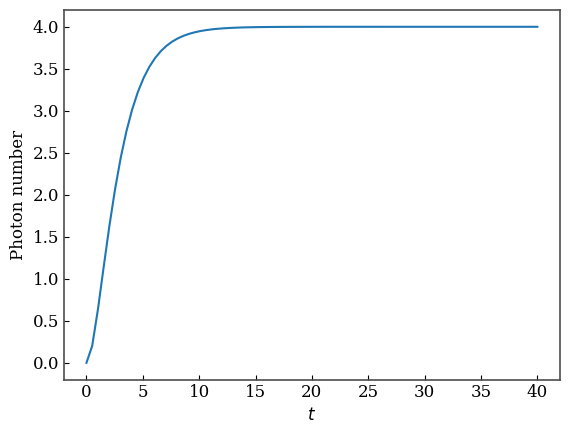

In [ ]:
fig, axes = plt.subplots(1, 1)
axes.plot(tlist, result.expect[0])
axes.set_xlabel("$t$")
axes.set_ylabel("Photon number")

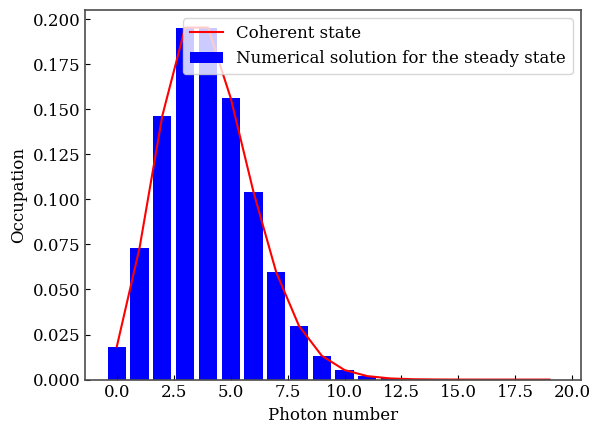

In [ ]:
alpha = np.sqrt(n_steady)
psi_coherent = coherent(N, alpha)

occupation_list = []
occupation_coherent = []
for i in range(N):
  psi = fock(N, i)
  occupation_list.append(np.abs((psi.dag() * result.states[-1])[0, 0]) ** 2)
  occupation_coherent.append(np.abs((psi.dag() * psi_coherent)) ** 2)

normalization = sum(occupation_list)
occupation_list = np.array(occupation_list)/normalization

fig, axes = plt.subplots(1, 1)
axes.bar(range(N), occupation_list, color = "blue",
         label="Numerical solution for the steady state")
axes.plot(range(N), occupation_coherent, color="red",
          label="Coherent state")
axes.set_xlabel("Photon number")
axes.set_ylabel("Occupation")
axes.legend()
plt.show()


### Fancy plots (asked Claude to help me)

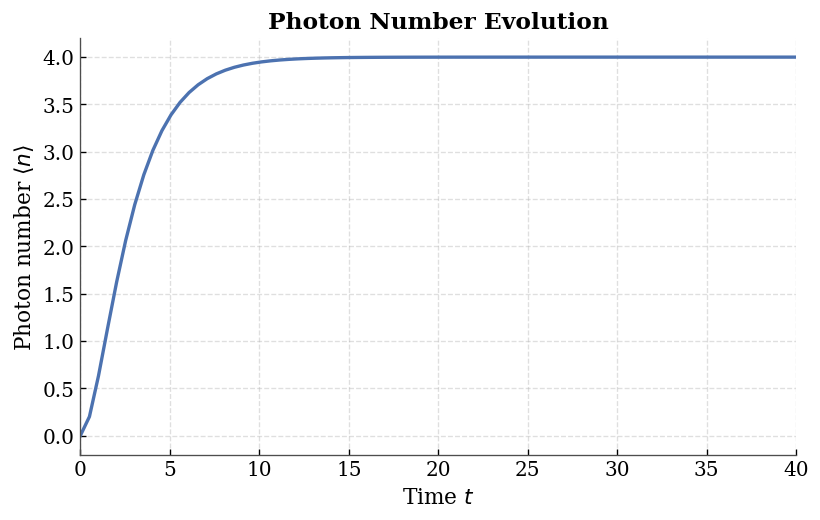

In [ ]:
plt.rcParams.update({
    "font.size": 12,
    "axes.edgecolor": "0.3",
    "axes.linewidth": 0.8,
})

fig, ax = plt.subplots(1, 1, figsize=(7, 4.5), dpi=120)

ax.plot(
    tlist, result.expect[0],
    color="#4C72B0",
    linewidth=2,
)

ax.set_xlabel("Time $t$", fontsize=13)
ax.set_ylabel("Photon number $\\langle n \\rangle$", fontsize=13)
ax.set_title("Photon Number Evolution", fontsize=14, fontweight="bold")

ax.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.set_xlim(tlist[0], tlist[-1])

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

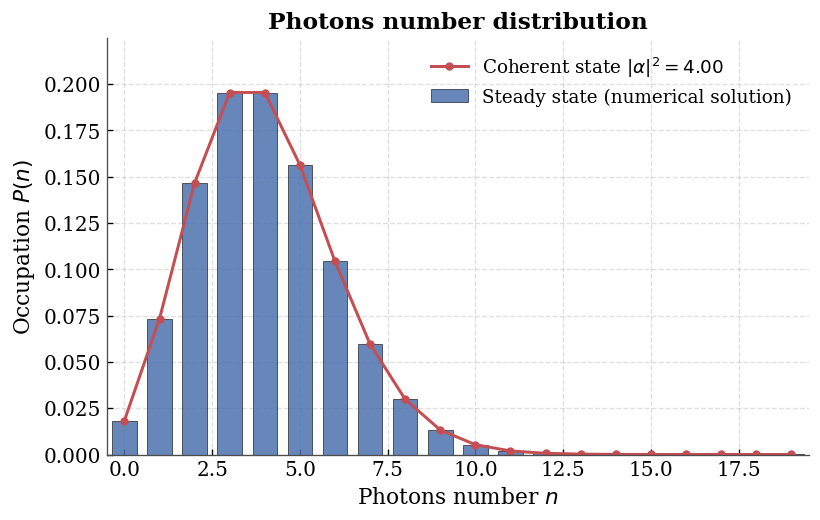

In [ ]:
plt.rcParams.update({
    "font.size": 12,
    "axes.edgecolor": "0.3",
    "axes.linewidth": 0.8,
})

fig, ax = plt.subplots(1, 1, figsize=(7, 4.5), dpi=120)

ax.bar(
    range(N), occupation_list,
    width=0.7,
    color="#4C72B0",
    edgecolor="black",
    linewidth=0.4,
    alpha=0.85,
    label="Steady state (numerical solution)"
)

ax.plot(
    range(N), occupation_coherent,
    color="#C44E52",
    marker="o",
    markersize=4,
    linewidth=1.8,
    label=fr"Coherent state $|\alpha|^2 = {n_steady:.2f}$"
)


ax.set_xlabel("Photons number $n$", fontsize=13)
ax.set_ylabel("Occupation $P(n)$", fontsize=13)
ax.set_title("Photons number distribution", fontsize=14, fontweight="bold")


ax.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)


ax.set_xlim(-0.5, N - 0.5)
ax.set_ylim(0, max(max(occupation_list), max(occupation_coherent)) * 1.15)


ax.legend(frameon=False, fontsize=11)

# Rimuovi bordi superflui
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# 4. Coupling
$$\hat{H}'=\hbar (\omega_c-\omega) \hat{a}^\dagger\hat{a} + \hbar (\omega_a-\omega) |e\rangle \langle e | + \hbar \tilde{g}(\hat{\sigma}_+  \hat{a}+ \hat{\sigma}_- \hat{a}^\dagger) + \varepsilon (\hat{a} + \hat{a}^\dagger)$$

$$\omega = \omega_0 - g$$

Then:
$$\hat{H}'=\hbar \tilde{g} \hat{a}^\dagger\hat{a} + \hbar \tilde{g} |e\rangle \langle e | + \hbar \tilde{g}(\hat{\sigma}_+  \hat{a}+ \hat{\sigma}_- \hat{a}^\dagger) + \varepsilon (\hat{a} + \hat{a}^\dagger)$$

In [ ]:
#hamiltonian params
g_tilde = 1.0                 #Rabi freq.
gamma = 0.05 * g_tilde        #atom decay
kappa = 0.05 * g_tilde        #cavity decay
epsilon = 0.05 * g_tilde            #pumping strenght

N = 20                        #hilbert space dimension

#hamiltonian's operators
a  = tensor(destroy(N), identity(2))
sm = tensor(identity(N), destroy(2))
atom = sm.dag() * sm


#collapse operator for the system
c_ops = [np.sqrt(kappa)*a, np.sqrt(gamma)*sm]

#hamiltonian defined as ahead
H = (g_tilde * a.dag()*a                  #cavity
     + g_tilde * atom                     #atom
     + g_tilde * (sm.dag()*a + sm*a.dag())#atom-light interaction
     + epsilon * (a + a.dag()))           #drive

#initial state
psi0 = tensor(basis(N,0), basis(2,0))  # |g,0>


tlist = np.linspace(0, 150, 300)
#i used option because for instable values of epsilon it stabilizes the computation
options = {"nsteps": 100000, "store_states": True}

result_eps_005 = mesolve(H, psi0, tlist, c_ops, e_ops=[a.dag()*a], options=options)
n_photons = result_eps_005.expect[0]
print(f"Steady number of photons:  {n_photons[-1]}")

Steady number of photons:  0.20798371615719394


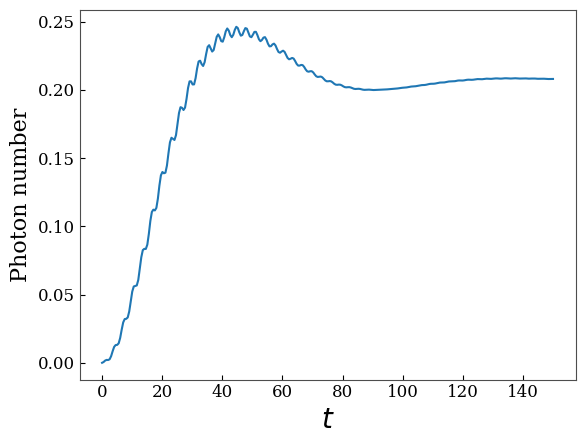

In [ ]:
fig, axes = plt.subplots(1, 1)
axes.plot(tlist, result_eps_005.expect[0])
axes.set_xlabel(r"$t$", fontsize=20)
axes.set_ylabel(r"Photon number", fontsize=16);

## How does $\varepsilon$ affects the result?

Let's rewrite the Hamiltonian in a perturbative way:

$$
H = \hbar g(a^\dagger a + |e\rangle\langle e| + \sigma_+ a + \sigma_- a^\dagger) + \varepsilon(a + a^\dagger) = H_0 + \varepsilon V
$$

$$
E_\pm^{(n)(0-th \ corr.)} = n\hbar g + 0 \pm \frac{\hbar}{2}\sqrt{g^2 n} = \sqrt{n}\,\hbar g\left(\sqrt{n} \pm \frac{1}{2}\right)
$$

$$
\theta = \arctan\left(\frac{g\sqrt{n}}{\delta}\right) \qquad \delta = 0 \implies \theta = \frac{\pi}{2}
$$

$$
|+\rangle^{(n)} = \frac{1}{\sqrt{2}}\left(|g,n\rangle + |e,n-1\rangle\right)
\qquad
|-\rangle^{(n)} = \frac{1}{\sqrt{2}}\left(-|g,n\rangle + |e,n\rangle\right)
$$

Let's compute the projector on the eigenvalue $E^{(n)(0-th \ corr.)}_+$
$\Pi_{E^{(n)(0-th \ corr.)}_+} = \dfrac{1}{2}\left(|g,n\rangle\langle g,n| + |g,n\rangle\langle e,n-1| + |e,n-1\rangle\langle g,n| + |e,n-1\rangle\langle e,n-1|\right)$

Since $a$ and $a^\dagger$ act just on the Fock state, we obtain only orthogonal products

$$
\implies H^{(1)} = 0 \implies \text{No first order correction}
$$

### Second order correction

## Second Order for $n = 1$

$$
|+\rangle^{(1)} = \frac{1}{\sqrt2}\big(|g,1\rangle + |e,0\rangle\big), \qquad E_+^{(1)} = \frac{3}{2}\hbar g
$$
$$
|-\rangle^{(1)} = \frac{1}{\sqrt2}\big(-|g,1\rangle + |e,0\rangle\big), \qquad E_-^{(1)} = \frac{1}{2}\hbar g
$$

Using $V$ we can access the states ($n = 0$ e $n = 2$):

$$
|g,0\rangle \ (E=0), \qquad
|+\rangle^{(2)} = \tfrac{1}{\sqrt2}(|g,2\rangle + |e,1\rangle) \ \Big(E_+^{(2)} = \sqrt2\,\hbar g(\sqrt2+\tfrac12)\Big)
$$
$$
|-\rangle^{(2)} = \tfrac{1}{\sqrt2}(-|g,2\rangle + |e,1\rangle) \ \Big(E_-^{(2)} = \sqrt2\,\hbar g(\sqrt2-\tfrac12)\Big)
$$

Let's compute the elements of $V$ matrix

Reminding that $a|n\rangle = \sqrt{n}\,|n-1\rangle$, $a^\dagger|n\rangle = \sqrt{n+1}\,|n+1\rangle$:

$$
\langle g,0|V|+\rangle^{(1)} = \frac{1}{\sqrt2}, \qquad \langle g,0|V|-\rangle^{(1)} = -\frac{1}{\sqrt2}
$$

$$
\langle +^{(2)}|V|+\rangle^{(1)} = \frac12(\sqrt2+1), \qquad \langle -^{(2)}|V|+\rangle^{(1)} = \frac12(1-\sqrt2)
$$

$$
\langle +^{(2)}|V|-\rangle^{(1)} = \frac12(1-\sqrt2), \qquad \langle -^{(2)}|V|-\rangle^{(1)} = \frac12(\sqrt2+1)
$$

### Corrections

Using the general formula
$$
H^{(2)}_{ab} = \sum_{m} \frac{\langle a|V|m\rangle\langle m|V|b\rangle}{E_a^{(0)} - E_m^{(0)}}
$$

For a $a=b=+\Rightarrow H^{(2)}_{++}$ and $a=+,\,b=-\Rightarrow H^{(2)}_{+-}$, summing on  $m = g_0,\ +^{(2)},\ -^{(2)}$:

$|g,0\rangle$:
$$
\frac{(1/\sqrt2)(-1/\sqrt2)}{\tfrac32\hbar g - 0} = -\frac{1}{3\hbar g}
$$

$|+\rangle^{(2)}$:
$$
\frac{\tfrac14(\sqrt2+1)(1-\sqrt2)}{\tfrac32\hbar g - \sqrt2\hbar g(\sqrt2+\tfrac12)} = \frac{-1/4}{-\big(\tfrac12+\tfrac{\sqrt2}{2}\big)\hbar g}
$$

$|-\rangle^{(2)}$:
$$
\frac{\tfrac14(1-\sqrt2)(\sqrt2+1)}{\tfrac32\hbar g - \sqrt2\hbar g(\sqrt2-\tfrac12)} = \frac{-1/4}{\big(\tfrac{\sqrt2}{2}-\tfrac12\big)\hbar g}
$$


$$
H^{(2)}_{+-} \approx \approx -1.33\,\frac{\varepsilon^2}{g}
$$



## Conclusion

Let's define $\alpha$ so that $\varepsilon = \alpha g$ where $\alpha \ll 1$.

$$
H^{(2)}_{+-} \sim \frac{\varepsilon^2}{g} = \alpha^2 g, \qquad \Delta E = E_+^{(1)} - E_-^{(1)} = \hbar g
$$

The ratio:

$$
\frac{H^{(2)}_{+-}}{\Delta E} \sim \alpha^2 \ll 1
$$

Mixing angle between the true eigenstates:

$$
\tan(2\phi) = \frac{2\,H^{(2)}_{+-}}{\Delta E} \sim \alpha^2 \quad\implies\quad \phi \sim \alpha^2
$$

Energetic shift

$$
\delta E \approx \frac{\big(H^{(2)}_{+-}\big)^2}{\Delta E} \sim \frac{(\alpha^2 g)^2}{g} = \alpha^4 g = O(\alpha^4)
$$


With precision $O(\alpha)$ we can ignore the correction and continue to consider H' diagonal in $| + \rangle$ and $| - \rangle$



In [ ]:
epsilon_list = [i*g_tilde for i in np.logspace(-4, 1, 10)]

results = []
for epsilon in epsilon_list:
  H = (g_tilde * a.dag()*a
     + g_tilde * atom
     + g_tilde * (sm.dag()*a + sm*a.dag())
     + epsilon * (a + a.dag()))
  result = mesolve(H, psi0, tlist, c_ops, e_ops=[a.dag()*a], options=options)
  results.append(result)


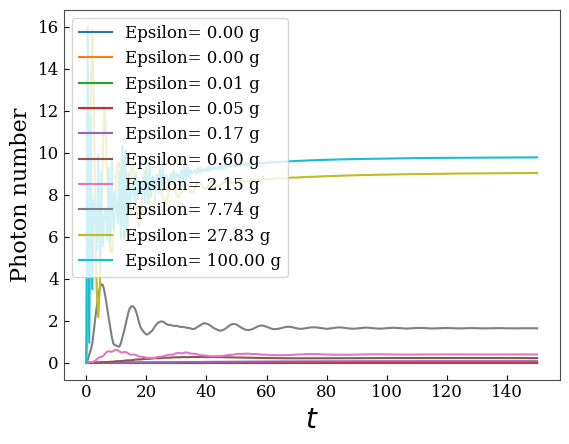

In [ ]:
fig, axes = plt.subplots(1, 1)
for r, e in zip(results, np.logspace(-3, 2, 10)):
  axes.plot(tlist, r.expect[0], label=f"Epsilon= {e:.2f} g")

axes.set_xlabel(r"$t$", fontsize=20)
axes.set_ylabel(r"Photon number", fontsize=16)
axes.legend()

### Fancy plot (asked Claude to help me)

/tmp/ipykernel_1858/1108106804.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


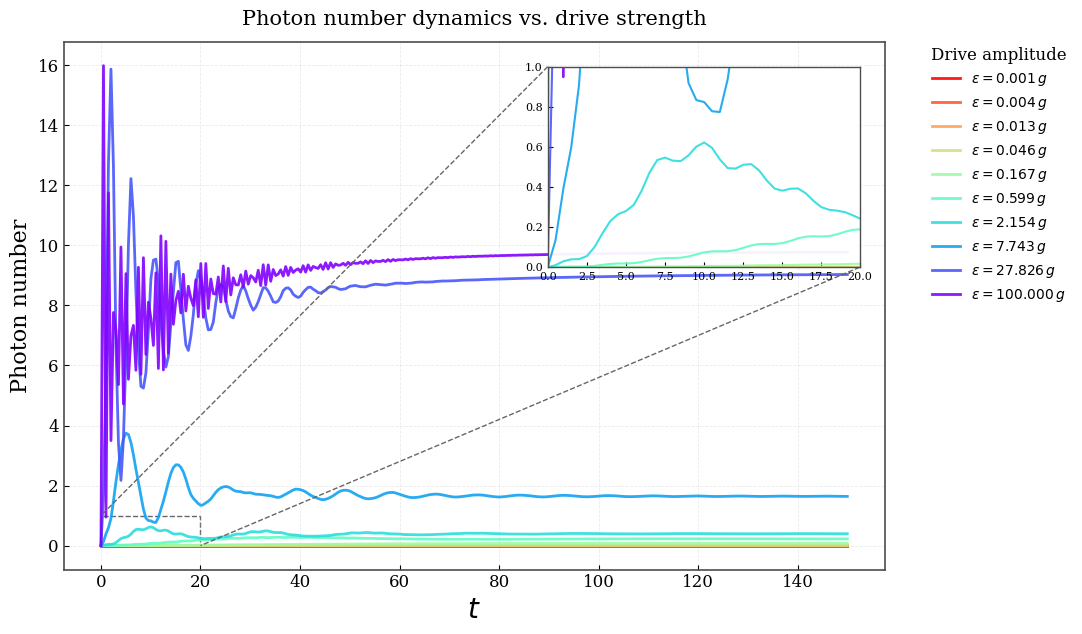

In [ ]:
# --- Stile generale ---
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['axes.linewidth'] = 1.2
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'

fig, axes = plt.subplots(1, 1, figsize=(11, 6.5))

epsilons = np.logspace(-3, 2, 10)
colors = plt.cm.rainbow_r(np.linspace(0, 1, len(epsilons)))

for r, e, c in zip(results, epsilons, colors):
    axes.plot(tlist, r.expect[0], label=f"$\\varepsilon = {e:.3f}\\,g$",
              color=c, linewidth=2, alpha=0.9)

# --- Inset ---
ax_inset = inset_axes(axes, width="38%", height="38%", loc="upper right",
                       borderpad=1.5)

for r, c in zip(results, colors):
    ax_inset.plot(tlist, r.expect[0], color=c, linewidth=1.5, alpha=0.9)

ax_inset.set_xlim(0, 20)
ax_inset.set_ylim(0, 1)
ax_inset.tick_params(axis="both", which="major", labelsize=8)
ax_inset.set_facecolor('white')
ax_inset.patch.set_alpha(0.95)
for spine in ax_inset.spines.values():
    spine.set_linewidth(1)

mark_inset(axes, ax_inset, loc1=2, loc2=4, fc="none", ec="0.4", ls="--", lw=1)

# --- Assi principali ---
axes.set_xlabel(r"$t$", fontsize=20)
axes.set_ylabel("Photon number", fontsize=16)
axes.tick_params(axis='both', which='major', labelsize=12)
axes.grid(True, alpha=0.25, linestyle='--', linewidth=0.6)
axes.set_title("Photon number dynamics vs. drive strength", fontsize=15, pad=12)

axes.legend(loc="upper left", bbox_to_anchor=(1.05, 1), borderaxespad=0.0,
            frameon=False, fontsize=10, title=r"Drive amplitude")

plt.tight_layout()
plt.show()

### Comments

We observe as expected that for $\varepsilon << g$ the dynamic is not influenced much: the frequency of the system remains the same, what changes is the number of photons in the steady state.

# 5. Is it possible to have two photons?


As was said previously (Section. 4) the probability of having two photons in the cavity is negligible since the mixing angle between states goes as $\alpha^2 = \left( \frac{\varepsilon}{g} \right)$. We can consider in the case of weak drive that the hamiltonian is still diagonal in $|+ \rangle$ and $|+ \rangle$

## How do the other parameters influence the dynamic of the system?

As you can see in the following plots, $\tilde{g}$ acts on the frequency of the system, while $\Gamma, \kappa$ on the decay time.

In [ ]:
#hamiltonian params
g_tilde_list = np.linspace(0.1, 3, 5)                #Rabi freq.
gamma = 0.05 * g_tilde       #atom decay
kappa = 0.05 * g_tilde        #cavity decay
N = 20                        #hilbert space dimension

#hamiltonian's operators
a  = tensor(destroy(N), identity(2))
sm = tensor(identity(N), destroy(2))
atom = sm.dag() * sm



psi0 = tensor(basis(N,0), basis(2,1))  # |g,0>

results=[]

tlist = np.linspace(0, 150, 300)
#i used option because for instable values of epsilon it stabilizes the computation
options = {"nsteps": 100000, "store_states": True}
for g in g_tilde_list:

  epsilon = 0.05 * g            #pumping strenght
  #collapse operator for the system
  c_ops = [np.sqrt(kappa)*a, np.sqrt(gamma)*sm]

  H = (g * a.dag()*a
     + g * atom
     + g * (sm.dag()*a + sm*a.dag())
     + epsilon * (a + a.dag()))
  result = mesolve(H, psi0, tlist, c_ops, e_ops=[a.dag()*a], options=options)
  results.append(result)

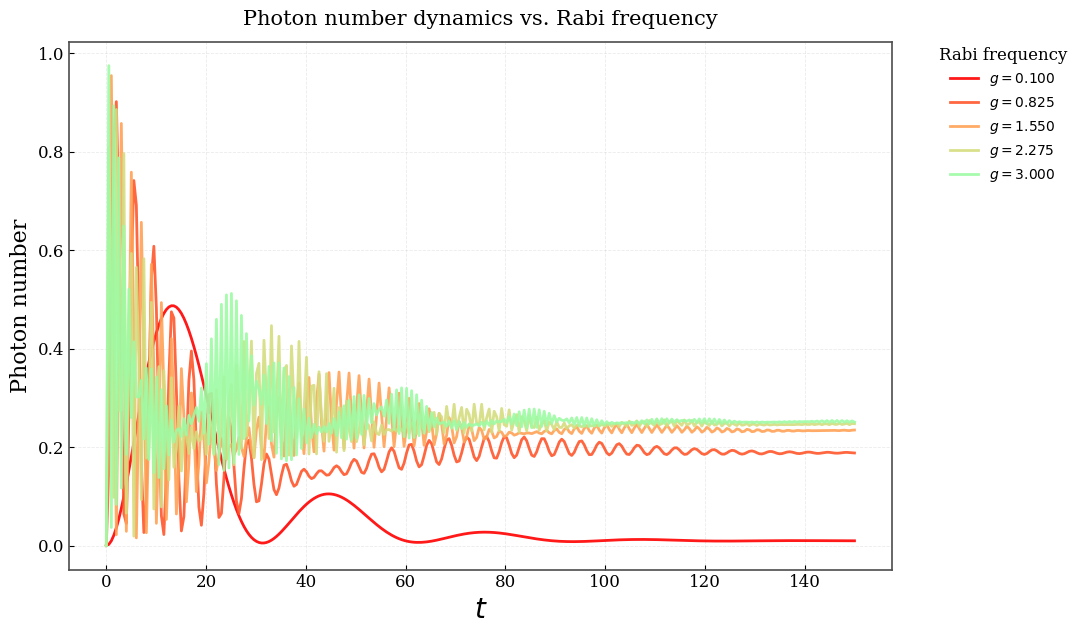

In [ ]:
# --- Stile generale ---
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['axes.linewidth'] = 1.2
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'

fig, axes = plt.subplots(1, 1, figsize=(11, 6.5))

colors = plt.cm.rainbow_r(np.linspace(0, 1, len(epsilons)))

for r, e, c in zip(results, g_tilde_list, colors):
    axes.plot(tlist, r.expect[0], label=f"$ g = {e:.3f}$",
              color=c, linewidth=2, alpha=0.9)

for r, c in zip(results, colors):
    ax_inset.plot(tlist, r.expect[0], color=c, linewidth=1.5, alpha=0.9)


# --- Assi principali ---
axes.set_xlabel(r"$t$", fontsize=20)
axes.set_ylabel("Photon number", fontsize=16)
axes.tick_params(axis='both', which='major', labelsize=12)
axes.grid(True, alpha=0.25, linestyle='--', linewidth=0.6)
axes.set_title("Photon number dynamics vs. Rabi frequency", fontsize=15, pad=12)

axes.legend(loc="upper left", bbox_to_anchor=(1.05, 1), borderaxespad=0.0,
            frameon=False, fontsize=10, title=r"Rabi frequency")

plt.tight_layout()
plt.show()

In [ ]:
#hamiltonian params
g_tilde = 1              #Rabi freq.
gamma_list = 0.05 * np.linspace(0.1, 3, 5)       #atom decay
kappa_list = 0.05 * np.linspace(0.1, 3, 5)       #cavity decay
epsilon = 0.05 * g_tilde         #pumping strenght
N = 20                                      #hilbert space dimension

#hamiltonian's operators
a  = tensor(destroy(N), identity(2))
sm = tensor(identity(N), destroy(2))
atom = sm.dag() * sm



psi0 = tensor(basis(N,0), basis(2,1))  # |g,0>

results=[]

tlist = np.linspace(0, 150, 300)
#i used option because for instable values of epsilon it stabilizes the computation
options = {"nsteps": 100000, "store_states": True}
for g, k in zip(gamma_list, kappa_list):
  #collapse operator for the system
  c_ops = [np.sqrt(k)*a, np.sqrt(g)*sm]

  H = (g_tilde * a.dag()*a
     + g_tilde * atom
     + g_tilde * (sm.dag()*a + sm*a.dag())
     + epsilon * (a + a.dag()))
  result = mesolve(H, psi0, tlist, c_ops, e_ops=[a.dag()*a], options=options)
  results.append(result)

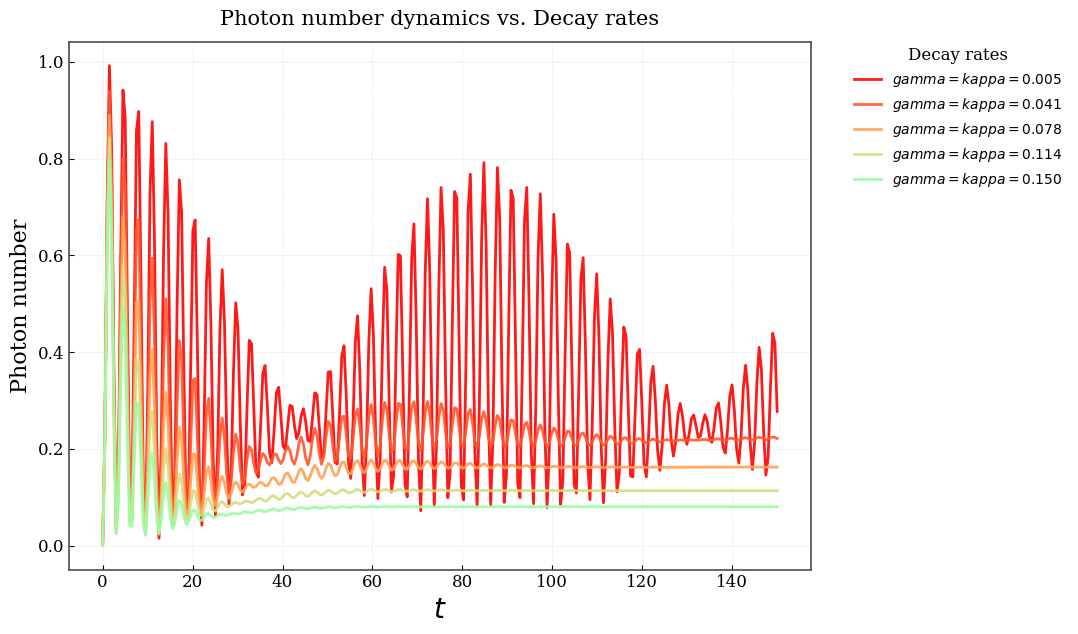

In [ ]:
# --- Stile generale ---
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['axes.linewidth'] = 1.2
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'

fig, axes = plt.subplots(1, 1, figsize=(11, 6.5))

colors = plt.cm.rainbow_r(np.linspace(0, 1, len(epsilons)))

for r, e, c in zip(results, gamma_list, colors):
    axes.plot(tlist, r.expect[0], label=f"$ gamma = kappa = {e:.3f}$",
              color=c, linewidth=2, alpha=0.9)

for r, c in zip(results, colors):
    ax_inset.plot(tlist, r.expect[0], color=c, linewidth=1.5, alpha=0.9)


# --- Assi principali ---
axes.set_xlabel(r"$t$", fontsize=20)
axes.set_ylabel("Photon number", fontsize=16)
axes.tick_params(axis='both', which='major', labelsize=12)
axes.grid(True, alpha=0.25, linestyle='--', linewidth=0.6)
axes.set_title("Photon number dynamics vs. Decay rates", fontsize=15, pad=12)

axes.legend(loc="upper left", bbox_to_anchor=(1.05, 1), borderaxespad=0.0,
            frameon=False, fontsize=10, title=r"Decay rates")

plt.tight_layout()
plt.show()

In [ ]:
#hamiltonian params
g_tilde_list = np.linspace(0.1, 3, 5)                #Rabi freq.

N = 20                        #hilbert space dimension

#hamiltonian's operators
a  = tensor(destroy(N), identity(2))
sm = tensor(identity(N), destroy(2))
atom = sm.dag() * sm



psi0 = tensor(basis(N,0), basis(2,1))  # |g,0>

results=[]

tlist = np.linspace(0, 150, 300)
#i used option because for instable values of epsilon it stabilizes the computation
options = {"nsteps": 100000, "store_states": True}
for g in g_tilde_list:
  gamma = 0.05 * g       #atom decay
  kappa = 0.05 * g        #cavity decay
  epsilon = 0.05 * g            #pumping strenght
  #collapse operator for the system
  c_ops = [np.sqrt(kappa)*a, np.sqrt(gamma)*sm]

  H = (g * a.dag()*a
     + g * atom
     + g * (sm.dag()*a + sm*a.dag())
     + epsilon * (a + a.dag()))
  result = mesolve(H, psi0, tlist, c_ops, e_ops=[a.dag()*a], options=options)
  results.append(result)

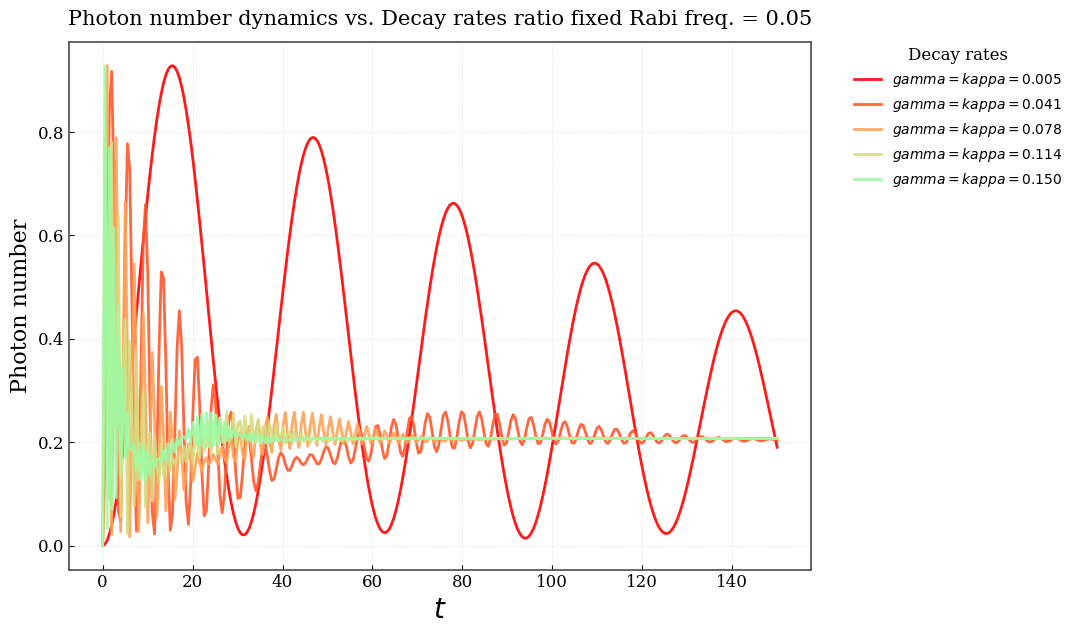

In [ ]:
# --- Stile generale ---
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['axes.linewidth'] = 1.2
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'

fig, axes = plt.subplots(1, 1, figsize=(11, 6.5))

colors = plt.cm.rainbow_r(np.linspace(0, 1, len(epsilons)))

for r, e, c in zip(results, gamma_list, colors):
    axes.plot(tlist, r.expect[0], label=f"$ gamma = kappa = {e:.3f}$",
              color=c, linewidth=2, alpha=0.9)

for r, c in zip(results, colors):
    ax_inset.plot(tlist, r.expect[0], color=c, linewidth=1.5, alpha=0.9)


# --- Assi principali ---
axes.set_xlabel(r"$t$", fontsize=20)
axes.set_ylabel("Photon number", fontsize=16)
axes.tick_params(axis='both', which='major', labelsize=12)
axes.grid(True, alpha=0.25, linestyle='--', linewidth=0.6)
axes.set_title("Photon number dynamics vs. Decay rates ratio fixed Rabi freq. = 0.05", fontsize=15, pad=12)

axes.legend(loc="upper left", bbox_to_anchor=(1.05, 1), borderaxespad=0.0,
            frameon=False, fontsize=10, title=r"Decay rates")

plt.tight_layout()
plt.show()

# 6. Two photons correlation function

In [ ]:
#hamiltonian params
g_tilde = 1.0                 #Rabi freq.
gamma = 0.05 * g_tilde        #atom decay
kappa = 0.05 * g_tilde        #cavity decay
epsilon = 0.05 * g_tilde            #pumping strenght

N = 20                        #hilbert space dimension

#hamiltonian's operators
a  = tensor(destroy(N), identity(2))
sm = tensor(identity(N), destroy(2))
atom = sm.dag() * sm


#collapse operator for the system
c_ops = [np.sqrt(kappa)*a, np.sqrt(gamma)*sm]

#hamiltonian defined as ahead
H = (g_tilde * a.dag()*a                  #cavity
     + g_tilde * atom                     #atom
     + g_tilde * (sm.dag()*a + sm*a.dag())#atom-light interaction
     + epsilon * (a + a.dag()))           #drive

g2, G2 = coherence_function_g2(H, None, [0], c_ops, a)
#initial state
psi0 = tensor(basis(N,0), basis(2,1))  # |g,0>


tlist = np.linspace(0, 150, 300)
#i used option because for instable values of epsilon it stabilizes the computation
options = {"nsteps": 100000, "store_states": True}

result_eps_005 = mesolve(H, psi0, tlist, c_ops, e_ops=[a.dag()*a], options=options)
n_photons = result_eps_005.expect[0]
print(f"Steady number of photons:  {g2}")

Steady number of photons:  [0.10499088+0.j]


/tmp/ipykernel_1858/2921284849.py:9: RuntimeWarning: invalid value encountered in divide
  g2_num_expect = g2_num_expect / norm**2


Text(0, 0.5, '$g^{(2)}$')

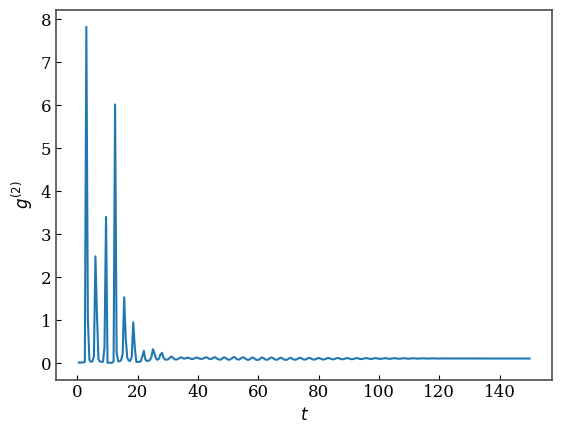

In [ ]:
g_2_operator  = a.dag()*a.dag()*a*a
g_2_operator_norm = a.dag()*a

states_vs_time = result_eps_005.states

norm = np.array(expect(g_2_operator_norm, states_vs_time))
g2_num_expect = np.array(expect(g_2_operator, states_vs_time))

g2_num_expect = g2_num_expect / norm**2

plt.plot(tlist, g2_num_expect)
plt.xlabel("$t$")
plt.ylabel("$g^{(2)}$")

#7. Scan the values of $\omega$ around the resonance and graphically represent your findings as in Fig. 2a of the paper by Birnbaum et al.

$$\hat{H}'=\hbar (\omega_0-\omega) \hat{a}^\dagger\hat{a} + \hbar (\omega_0-\omega) |e\rangle \langle e | + \hbar \tilde{g}(\hat{\sigma}_+  \hat{a}+ \hat{\sigma}_- \hat{a}^\dagger) + \varepsilon (\hat{a} + \hat{a}^\dagger)$$

 Where $\omega_a = \omega_c \equiv \omega_0$

In [ ]:
#hamiltonian params
g_tilde = 1.0                 #Rabi freq.
gamma = 0.05 * g_tilde        #atom decay
kappa = 0.05 * g_tilde        #cavity decay
epsilon = 0.05 * g_tilde            #pumping strenght

N = 20                        #hilbert space dimension

#hamiltonian's operators
a  = tensor(destroy(N), identity(2))
sm = tensor(identity(N), destroy(2))
atom = sm.dag() * sm



detuning = np.linspace(-1.5*g_tilde, 1.5*g_tilde, 100)
#collapse operator for the system
c_ops = [np.sqrt(kappa)*a, np.sqrt(gamma)*sm]
g2_list = []

for delta in detuning:
  #hamiltonian defined as ahead
  H = (delta * a.dag()*a                  #cavity
      + delta * atom                     #atom
      + g_tilde * (sm.dag()*a + sm*a.dag())#atom-light interaction
      + epsilon * (a + a.dag()))           #drive
  rho_ss = steadystate(H, c_ops)
  n_avg = expect(a.dag()*a, rho_ss)
  g2 = expect(a.dag()*a.dag()*a*a, rho_ss) / n_avg**2 if n_avg > 1e-6 else 0
  g2_list.append(g2)





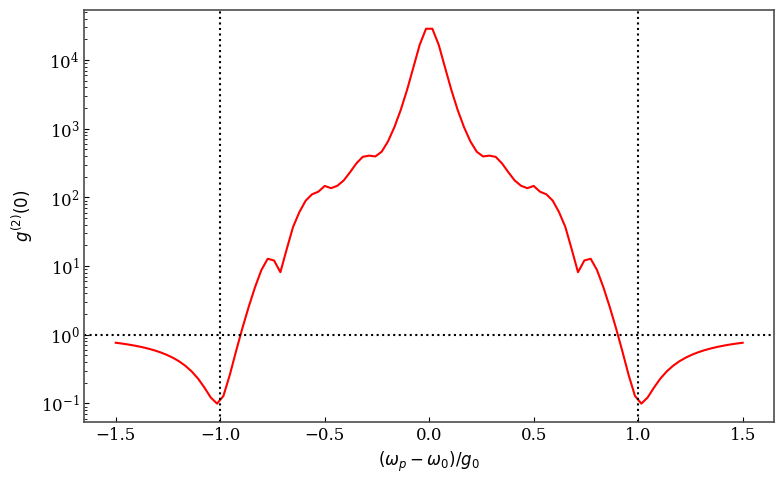

In [ ]:
g2_list = np.array(g2_list)


fig, ax = plt.subplots(1, 1, figsize=(8,5), sharex=True)
ax.semilogy(detuning/g_tilde, g2_list, 'red')
ax.axvline(-1, color='black', ls=':')
ax.axvline(1, color='black', ls=':')
ax.axhline(1, color='black', ls=':')
ax.set_xlabel(r'$(\omega_p-\omega_0)/g_0$')
ax.set_ylabel(r'$g^{(2)}(0)$')
ax.axhline(-1, color='black', ls=':')

plt.tight_layout()
plt.show()

# 8. *(Bonus)* Can you make analytical predictions for the steady state in a convenient regime?

# Steady state for the uncoupled hamiltonian and drive resonant to atom and cavity



## 3.1 Solving Bloch Optical Equations for the Cavity

Lindblad equation for our system.
$$\dot\rho = \frac{i}{\hbar}[\rho, H] + \frac{\kappa}{2}\left[2a\rho a^\dagger - \{a^\dagger a, \rho\}\right]$$

Our aim is to compute:
$$\frac{d}{dt}\langle a^\dagger a \rangle = \text{Tr}[\dot\rho\, a^\dagger a]$$

So that we can compute the value of $\langle a^\dagger a \rangle$ for the steady state as well.

### *First term*

$$\text{Tr}\left[\frac{i}{\hbar}[\rho,H]\,a^\dagger a\right] = \frac{i}{\hbar}\text{Tr}(\rho Ha^\dagger a) - \frac{i}{\hbar}\text{Tr}(\rho a^\dagger aH) = \frac{i}{\hbar}\text{Tr}\left(\rho[H, a^\dagger a]\right)$$

Con $H=\varepsilon(a+a^\dagger)$ e usando $[a,a^\dagger a]=a$, $[a^\dagger,a^\dagger a]=-a^\dagger$:

$$[H, a^\dagger a] = \varepsilon\left([a,a^\dagger a] + [a^\dagger,a^\dagger a]\right) = \varepsilon(a - a^\dagger)$$

$$\text{Tr}\left[\frac{i}{\hbar}[\rho,H]a^\dagger a\right] = \frac{i\varepsilon}{\hbar}\left(\langle a \rangle - \langle a^\dagger \rangle\right)$$

### *Second Term*

$$\frac{\kappa}{2}\text{Tr}\left[\left(2a\rho a^\dagger - a^\dagger a\rho - \rho a^\dagger a\right)a^\dagger a\right]$$

Using: $\text{Tr}(a\rho a^\dagger a^\dagger a)=\text{Tr}(\rho a^\dagger a^\dagger a a)$

$$= \kappa\,\text{Tr}\left(\rho a^\dagger a^\dagger a a\right) - \kappa\,\text{Tr}\left(\rho a^\dagger aa^\dagger a\right) = \kappa\,\text{Tr}\left[\rho a^\dagger\left(a^\dagger a a - a a^\dagger a\right)\right]$$

Con $a^\dagger aa - aa^\dagger a = (a^\dagger a - aa^\dagger)a = [a^\dagger,a]\,a=-a$:

$$= \kappa\,\text{Tr}\left[\rho a^\dagger(-a)\right] = -\kappa\,\text{Tr}(\rho a^\dagger a) = -\kappa\langle N \rangle$$

### *Final result*

$$\frac{d}{dt}\langle a^\dagger a \rangle = \frac{d}{dt}\langle N \rangle = \frac{i\varepsilon}{\hbar}\left(\langle a \rangle - \langle a^\dagger \rangle\right) - \kappa\langle N \rangle$$

We see that $\langle N \rangle$ depends on $\langle a \rangle$ and $\langle a^\dagger \rangle$. Let's compute the time derivative of these terms to solve the differential system.

---

$$\frac{d}{dt}\langle a \rangle = \text{Tr}[\dot\rho\, a]$$

### *First Term*

$$\text{Tr}\left(\frac{i}{\hbar}[\rho,H]a\right) = \frac{i}{\hbar}\text{Tr}(\rho Ha) - \frac{i}{\hbar}\text{Tr}(\rho aH) \quad \text{(using } \text{Tr}(ABC) = \text{Tr}(BCA)\text{)}$$

$$= \frac{i}{\hbar}\text{Tr}\left(\rho[H,a]\right)$$

Using $[H,a] = \varepsilon[a+a^\dagger, a] = \varepsilon[a^\dagger, a] = -\varepsilon$:

$$= \frac{i}{\hbar}\text{Tr}\left(\rho\cdot(-\varepsilon)\right) = -\frac{i\varepsilon}{\hbar}$$

### *Second term*

$$\frac{\kappa}{2}\text{Tr}\left[(2a\rho a^\dagger - a^\dagger a\rho - \rho a^\dagger a)a\right]$$

Using: $\text{Tr}(a\rho a^\dagger a)=\text{Tr}(\rho a^\dagger a\,a)$, $\text{Tr}(\rho a^\dagger a a)=\text{Tr}(\rho a^\dagger a\,a)$, and $\text{Tr}(a^\dagger a\rho a)=\text{Tr}(\rho a\,a^\dagger a)$:

$$= \frac{\kappa}{2}\left[2\,\text{Tr}(\rho a^\dagger a\, a) - \text{Tr}(\rho a\, a^\dagger a) - \text{Tr}(\rho a^\dagger a\, a)\right] = \frac{\kappa}{2}\text{Tr}\left(\rho[a^\dagger a,a]\right)$$

Con $\hat N=a^\dagger a$ e $[\hat N,a] = a^\dagger a a - a a^\dagger a = (a^\dagger a - aa^\dagger)a = -a$:

$$= \frac{\kappa}{2}\text{Tr}(-\rho a) = -\frac{\kappa}{2}\langle a \rangle$$

### *Result*

$$\frac{d}{dt}\langle a \rangle = -\frac{i\varepsilon}{\hbar} - \frac{\kappa}{2}\langle a \rangle$$

$$\frac{d}{dt}\langle a^\dagger \rangle = \frac{i\varepsilon}{\hbar} - \frac{\kappa}{2}\langle a^\dagger \rangle$$

---

### Computing the average value of photons for the steady state

$$\frac{d}{dt}\begin{pmatrix} \langle a \rangle \\ \langle a^\dagger \rangle \\ \langle N \rangle \end{pmatrix} = \begin{pmatrix} -\dfrac{\kappa}{2} & 0 & 0 \\[8pt] 0 & -\dfrac{\kappa}{2} & 0 \\[8pt] \dfrac{i\varepsilon}{\hbar} & -\dfrac{i\varepsilon}{\hbar} & -\kappa \end{pmatrix}\begin{pmatrix} \langle a \rangle \\ \langle a^\dagger \rangle \\ \langle N \rangle \end{pmatrix} + \begin{pmatrix} -\dfrac{i\varepsilon}{\hbar} \\[6pt] \dfrac{i\varepsilon}{\hbar} \\[6pt] 0 \end{pmatrix}$$

we define:
$$\vec S = \begin{pmatrix} \langle a \rangle \\ \langle a^\dagger \rangle \\ \langle N \rangle \end{pmatrix}, \qquad M = \begin{pmatrix} -\dfrac{\kappa}{2} & 0 & 0 \\[8pt] 0 & -\dfrac{\kappa}{2} & 0 \\[8pt] \dfrac{i\varepsilon}{\hbar} & -\dfrac{i\varepsilon}{\hbar} & -\kappa \end{pmatrix}, \qquad \vec R = \begin{pmatrix} -\dfrac{i\varepsilon}{\hbar} \\[6pt] \dfrac{i\varepsilon}{\hbar} \\[6pt] 0 \end{pmatrix}$$

For a steady state:

$$\frac{d}{dt} \vec S(t \rightarrow \infty) = 0= M\vec S + \vec R$$
$$\vec S_{ss} = -M^{-1}\vec R$$

$$\vec S_{ss} = \begin{pmatrix} -\dfrac{2i\varepsilon}{\hbar\kappa} \\[8pt] \dfrac{2i\varepsilon}{\hbar\kappa} \\[8pt] \dfrac{4\varepsilon^2}{\hbar^2\kappa^2} \end{pmatrix}$$

# Steady state for the hamiltonian with $\omega$ to resonant with the lowest (one-photon) dressed state


**NOTE** for the following I used $\langle \sigma_+ a \rangle= \langle \sigma_+ \rangle \langle a \rangle$ and $\langle \sigma_- a^\dagger \rangle= \langle \sigma_- \rangle \langle a^\dagger \rangle$ (I ignore the correlation between the two operators) since I noticed that otherwise we can't have a closed solution

The hamiltonian is the same we used since point 4:
$$H = \hbar g\left(|e\rangle\langle e| + a^\dagger a + \sigma_+ a + \sigma_- a^\dagger\right) + \varepsilon(a + a^\dagger)$$

The Lindblad eq. for a system with atom decay rate $\Gamma$ and cavity decay rate $\kappa$:

$$\dot\rho = \frac{i}{\hbar}[\rho, H] + \Gamma\left(\sigma_-\rho\sigma_+ - \frac{1}{2}\{\sigma_+\sigma_-,\rho\}\right) + \kappa\left(a\rho a^\dagger - \frac{1}{2}\{a^\dagger a,\rho\}\right)$$

## $\langle N \rangle$
We define $\hat N = |e\rangle\langle e| + a^\dagger a$ (number of excitations in the systems):

$$\langle \dot N\rangle = \text{Tr}(\dot\rho N) = \text{Tr}\left\{\underbrace{\frac{i}{\hbar}[\rho,H]\hat N}_{\text{I term}} + \underbrace{\Gamma\left(\sigma_-\rho\sigma_+ - \frac{1}{2}\{\sigma_+\sigma_-,\rho\}\right)}_{\text{II term}} + \underbrace{\kappa\left(a\rho a^\dagger - \frac{1}{2}\{a^\dagger a,\rho\}\right)}_{\text{III term}}\hat N\right\}$$


### I term

$$\text{Tr}\left[\frac{i}{\hbar}[\rho,H]N\right] = \text{Tr}\left[\frac{i}{\hbar}(\rho H - H\rho)N\right] = \text{Tr}\left[\frac{i}{\hbar}\rho H N\right] - \text{Tr}\left[\frac{i}{\hbar}H\rho N\right] = \text{Tr}\left[\frac{i}{\hbar}\rho H N\right] - \text{Tr}\left[\frac{i}{\hbar}\rho N H\right]$$

where I used trace ciclicity in the last passage:

$$= \text{Tr}\left(\frac{i}{\hbar}\rho[H,N]\right)$$

The commutator:

$$[H,N] = \hbar g([\sigma_+ a, N] + [\sigma_- a^\dagger, N]) + \varepsilon[a+a^\dagger, N]$$

$$= \hbar g\Big(\sigma_+ a[a,a^\dagger a]... \Big)$$

Since $N=|e\rangle\langle e|+a^\dagger a$ commutes with $\sigma_+\sigma_-$ and with $a^\dagger a$ separately, only the cross terms $\sigma_+ a$ and $\sigma_- a^\dagger$ can contribute, and in fact **they cancel each other**:

$$[\sigma_+ a, N] = -[\sigma_- a^\dagger, N] \quad\Rightarrow\quad \hbar g\big([\sigma_+ a,N]+[\sigma_- a^\dagger,N]\big) = 0$$

The only surviving piece is the drive term:

$$[a+a^\dagger,N] = [a+a^\dagger,a^\dagger a] = a - a^\dagger$$

So:

$$[H,N] = \varepsilon(a-a^\dagger)$$

Then:

$$= \frac{i \varepsilon}{\hbar}\text{Tr}(\rho(a-a^\dagger)) = \frac{i \varepsilon}{\hbar}(\langle a\rangle - \langle a^\dagger\rangle)$$


### II Term

$$\Gamma\,\text{Tr}\left(\left\{\sigma_-\rho\sigma_+ - \frac{1}{2}\{\sigma_+\sigma_-,\rho\}\right\}N\right) = \Gamma\,\text{Tr}(\rho\sigma_+N\sigma_-) - \frac{1}{2}\Gamma\,\text{Tr}(\rho N\sigma_+\sigma_-) - \frac{1}{2}\Gamma\,\text{Tr}(\rho\sigma_+\sigma_-N)$$

$$= \frac{\Gamma}{2}\text{Tr}(\rho[\sigma_+,N]\sigma_-) + \frac{\Gamma}{2}\text{Tr}(\rho\sigma_+[N,\sigma_-]) = -\frac{\Gamma}{2}\text{Tr}(\rho\sigma_+\sigma_-) - \frac{\Gamma}{2}\text{Tr}(\rho\sigma_+\sigma_-)$$

$$= -\Gamma\,\text{Tr}(\rho\sigma_+\sigma_-) = -\Gamma\,\text{Tr}(\rho|e\rangle\langle e|) = -\Gamma\frac{1 + \langle\sigma_z\rangle}{2}$$

### III term

Analogously:

$$= -\kappa\langle a^\dagger a\rangle$$

### Result
$$\boxed{\langle\dot{N}\rangle = \frac{i \varepsilon}{\hbar}(\langle a\rangle - \langle a^\dagger\rangle)  -\Gamma\frac{1 + \langle\sigma_z\rangle}{2}  -\kappa\langle a^\dagger a\rangle}$$

---

## $\langle\dot\sigma_z\rangle$


### I term
$$[H,\sigma_z] = \hbar g\Big([\sigma_+ a,\sigma_z] + [\sigma_- a^\dagger,\sigma_z]\Big) = \hbar g\Big(-2\sigma_+ a + 2\sigma_- a^\dagger\Big)$$

$\varepsilon(a+a^\dagger)$ commutes with $\sigma_z$:

$$\frac{i}{\hbar}\text{Tr}(\rho[H,\sigma_z]) = ig\Big(-2\langle\sigma_+ a\rangle + 2\langle\sigma_- a^\dagger\rangle\Big) = 2ig\Big(\langle\sigma_-\rangle\langle a^\dagger\rangle - \langle\sigma_+\rangle\langle a\rangle\Big) $$

### II term

$$\Gamma\,\text{Tr}\left[\sigma_-\rho\sigma_+\sigma_z - \frac{1}{2}\{\sigma_+\sigma_-,\rho\}\sigma_z\right] =\Gamma\,\text{Tr}\left[\rho\sigma_+\sigma_z\sigma_- - \frac{1}{2}(\rho \sigma_z \sigma_+\sigma_- + \rho \sigma_+\sigma_- \sigma_z) \right]=$$

$$=\Gamma\,\text{Tr}\left[-\rho\sigma_+\sigma_- - \frac{1}{2}(\rho \sigma_+\sigma_- + \rho \sigma_+\sigma_-) \right] =  -\Gamma\big(\langle\sigma_z\rangle + 1\big)$$


### III term
 $a,a^\dagger$ commute with $\sigma_z$. Then:

$$\kappa\,\text{Tr}\left[\left(a\rho a^\dagger - \frac12\{a^\dagger a,\rho\}\right)\sigma_z\right] = \kappa\,\text{Tr}\left[\rho\,\sigma_z\left(a^\dagger a - \frac12 a^\dagger a - \frac12 a^\dagger a\right)\right] = 0$$



## Result

$$\boxed{\langle\dot\sigma_z\rangle = 2ig\Big(\langle\sigma_-\rangle\langle a^\dagger\rangle - \langle\sigma_+\rangle\langle a\rangle\Big) - \Gamma\big(\langle\sigma_z\rangle+1\big)}$$


---

## $\langle a^\dagger a\rangle$

$$\text{Tr}[\rho[H,a^\dagger a]] =  \hbar g\text{Tr}\left(\rho\sigma_+[a,a^\dagger a] + \sigma_-[a^\dagger,a^\dagger a]\right) + \varepsilon\,\text{Tr}([a+a^\dagger,a^\dagger a])$$

using $[a,a^\dagger a] = a$, $[a^\dagger,a^\dagger a] = -a^\dagger$, $[a+a^\dagger,a^\dagger a] = a - a^\dagger$

$$= \hbar g(\langle\sigma_+\rangle\langle a\rangle - \langle\sigma_-\rangle\langle a^\dagger\rangle) + \varepsilon(\langle a\rangle - \langle a^\dagger\rangle)$$

Dissipative part:

$$\rho a^\dagger a^\dagger a a - \rho a^\dagger a a^\dagger a - \rho a^\dagger a a^\dagger a$$

$$\rho a^\dagger[a^\dagger,a]a = -\rho a^\dagger a$$

Then:

$$\boxed{\langle \dot{a^\dagger a}\rangle = i g(\langle\sigma_+\rangle\langle a\rangle - \langle\sigma_-\rangle\langle a^\dagger\rangle) + \frac{i\varepsilon}{\hbar}(\langle a\rangle - \langle a^\dagger\rangle) - \kappa\langle a^\dagger a\rangle}$$

---

## $\langle a\rangle$ and $\langle a^\dagger\rangle$

$$\langle\dot a\rangle = \text{Tr}(\dot\rho a) = \text{Tr}\left\{\frac{i}{\hbar}[\rho,H]a + \Gamma\left(\sigma_-\rho\sigma_+ - \frac{1}{2}\{\sigma_+\sigma_-,\rho\}\right)a + \kappa\left(a\rho a^\dagger - \frac{1}{2}\{a^\dagger a,\rho\}\right)a\right\}$$

### I term

$$\text{Tr}\left\{\frac{i}{\hbar}[\rho,H]\right\} = \text{Tr}\left\{\frac{i}{\hbar}\rho[H,a]\right\} = \text{Tr}\left\{\frac{i}{\hbar}\hbar g[\sigma_-a^\dagger,a]\right\} + \text{Tr}\left\{\frac{i}{\hbar}\varepsilon[a^\dagger,a]\right\} = -ig\langle\sigma_-\rangle - \frac{i}{\hbar}\varepsilon$$

### II term

$$\text{Tr} = 0$$

(it commutes, so you can check this term is null)

### III term

$$\text{Tr}\left[\kappa\left(\rho a^\dagger a a - \frac{1}{2}\rho a a^\dagger a - \frac{1}{2}\rho a^\dagger a a\right)\right] = \frac{\kappa}{2}\text{Tr}\left[\rho[a^\dagger,a]a\right] = -\frac{\kappa}{2}\langle a\rangle$$

### Results

$$\boxed{\langle \dot{a^\dagger}\rangle = ig\langle\sigma_+\rangle + \frac{i}{\hbar}\varepsilon - \frac{\kappa}{2}\langle a^\dagger\rangle}$$

$$\boxed{\langle \dot a\rangle = -i g \langle\sigma_-\rangle - \frac{i}{\hbar}\varepsilon - \frac{\kappa}{2}\langle a\rangle}$$

---

##$\langle \sigma_+\rangle$ and $\langle \sigma_-\rangle$

$$\langle\dot\sigma_+\rangle = \text{Tr}(\dot\rho\sigma_+) = \text{Tr}\left(\frac{i}{\hbar}\rho[H,\sigma_+]\right) + \frac{\Gamma}{2}\text{Tr}\left(\rho[\sigma_+\sigma_-\sigma_+ - \sigma_+\sigma_-\sigma_+]\right)$$

$$= i g\langle\sigma_+\rangle - ig\langle\sigma_z\rangle\langle a^\dagger\rangle + \frac{\Gamma}{2}\text{Tr}\left(\frac{\Gamma}{2}\rho\sigma_+|e\rangle\langle e|\right)$$

### Results

$$\boxed{\langle\dot\sigma_-\rangle = i g \langle\sigma_-\rangle + i g\langle\sigma_z\rangle\langle a\rangle + \frac{\Gamma}{2}\langle\sigma_-\rangle}$$

$$\boxed{\langle\dot\sigma_+\rangle = -i g\langle\sigma_+\rangle - i g\langle\sigma_z\rangle\langle a^\dagger\rangle - \frac{\Gamma}{2}\langle\sigma_+\rangle}$$



## Bloch Equations

$$\vec S = \begin{pmatrix} \langle a\rangle \\ \langle a^\dagger\rangle \\ \langle \sigma_-\rangle \\ \langle \sigma_+\rangle \\ \langle \sigma_z\rangle \\ \langle a^\dagger a\rangle \\ \langle N\rangle \end{pmatrix}$$



$$\dot{\vec S} = M\,\vec S \;+\; \vec N \;+\; \vec R$$


### Matrix M

$$M = \begin{pmatrix}
-\frac{\kappa}{2} & 0 & -ig & 0 & 0 & 0 & 0 \\
0 & -\frac{\kappa}{2} & 0 & ig & 0 & 0 & 0 \\
0 & 0 & ig-\frac{\Gamma}{2} & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & -ig-\frac{\Gamma}{2} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & -\Gamma & 0 & 0 \\
\frac{i\varepsilon}{\hbar} & -\frac{i\varepsilon}{\hbar} & 0 & 0 & 0 & -\kappa & 0 \\
\frac{i\varepsilon}{\hbar} & -\frac{i\varepsilon}{\hbar} & 0 & 0 & -\frac{\Gamma}{2} & -\kappa & 0
\end{pmatrix}$$

### Nonlinear term

$$\vec N = \begin{pmatrix}
0 \\
0 \\
ig\,\langle a\rangle\langle\sigma_z\rangle \\
-ig\,\langle a^\dagger\rangle\langle\sigma_z\rangle \\
2ig\big(\langle\sigma_-\rangle\langle a^\dagger\rangle - \langle\sigma_+\rangle\langle a\rangle\big) \\
ig\big(\langle\sigma_+\rangle\langle a\rangle - \langle\sigma_-\rangle\langle a^\dagger\rangle\big) \\
0
\end{pmatrix}$$

### Constant term

$$\vec R = \begin{pmatrix}
-\dfrac{i\varepsilon}{\hbar} \\[4pt]
\dfrac{i\varepsilon}{\hbar} \\[4pt]
0 \\[4pt]
0 \\[4pt]
-\Gamma \\[4pt]
0 \\[4pt]
-\dfrac{\Gamma}{2}
\end{pmatrix}$$

## Full Explicit Form

$$\begin{pmatrix} \langle\dot a\rangle \\ \langle\dot a^\dagger\rangle \\ \langle\dot\sigma_-\rangle \\ \langle\dot\sigma_+\rangle \\ \langle\dot\sigma_z\rangle \\ \langle\dot{a^\dagger a}\rangle \\ \langle\dot N\rangle \end{pmatrix} = \begin{pmatrix}
-\frac{\kappa}{2} & 0 & -ig & 0 & 0 & 0 & 0 \\
0 & -\frac{\kappa}{2} & 0 & ig & 0 & 0 & 0 \\
0 & 0 & ig-\frac{\Gamma}{2} & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & -ig-\frac{\Gamma}{2} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & -\Gamma & 0 & 0 \\
\frac{i\varepsilon}{\hbar} & -\frac{i\varepsilon}{\hbar} & 0 & 0 & 0 & -\kappa & 0 \\
\frac{i\varepsilon}{\hbar} & -\frac{i\varepsilon}{\hbar} & 0 & 0 & -\frac{\Gamma}{2} & -\kappa & 0
\end{pmatrix}
\begin{pmatrix} \langle a\rangle \\ \langle a^\dagger\rangle \\ \langle \sigma_-\rangle \\ \langle \sigma_+\rangle \\ \langle \sigma_z\rangle \\ \langle a^\dagger a\rangle \\ \langle N\rangle \end{pmatrix}
+ \begin{pmatrix}
0 \\
0 \\
ig\,\langle a\rangle\langle\sigma_z\rangle \\
-ig\,\langle a^\dagger\rangle\langle\sigma_z\rangle \\
2ig\big(\langle\sigma_-\rangle\langle a^\dagger\rangle-\langle\sigma_+\rangle\langle a\rangle\big) \\
ig\big(\langle\sigma_+\rangle\langle a\rangle-\langle\sigma_-\rangle\langle a^\dagger\rangle\big) \\
0
\end{pmatrix}
+ \begin{pmatrix}
-\frac{i\varepsilon}{\hbar} \\
\frac{i\varepsilon}{\hbar} \\
0 \\
0 \\
-\Gamma \\
0 \\
-\frac{\Gamma}{2}
\end{pmatrix}$$


As you can see, this form is not linearly solvable. This has to be solved numerically, so there is no real advantage with respect to the simulation I've done previously.